In [1]:
!pip install -q xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier

import joblib

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pandas as pd

diagnostic_path = "/content/drive/MyDrive/AutoSenseAI/data/ML Car Diagnostic Agent AI Assistant.csv"

df = pd.read_csv(diagnostic_path)

df.head()

,Record ID,Car Name,Problem Classification,Problem Description,Severity,Diagnosis,How to Fix the Problem,Solution Used,ECU Data,Service History,Repair Status,Results
0,1,Honda Civic 2019,Electrical,Headlights flicker,Medium,Loose wiring,Check and repair loose or damaged wiring conne...,Check and repair wiring,NaN,Spark plugs replaced 2 years ago,Fixed,Resolved
1,2,Toyota Corolla 2018,Electrical,Power window failure,Medium,Window regulator motor,Check and repair loose or damaged wiring conne...,Check and repair wiring,Multiple codes,Spark plugs replaced 2 years ago,Fixed,Resolved
2,3,BMW i4 2019,Engine,Engine misfire,High,Timing belt failure,Replace spark plugs,Replaced failure,P0101,Regular maintenance,Fixed,Resolved
3,4,Nissan Rogue 2020,Transmission,Transmission overheating,High,Transmission fluid thick,Perform transmission service and inspect for i...,Perform transmission service,NaN,Spark plugs replaced 2 years ago,Fixed,Resolved
4,5,Mercedes S-Class 2020,Battery,Battery drains fast,High,Dead battery,Replace battery and test charging system,Replaced battery,NaN,Brake service 1 year ago,Fixed,Resolved


In [6]:
print(df.shape)

print(df.columns)

print(df.isnull().sum())

print(df["Problem Classification"].value_counts())

(10000, 12)
Index(['Record ID', 'Car Name', 'Problem Classification',
       'Problem Description', 'Severity', 'Diagnosis',
       'How to Fix the Problem', 'Solution Used', 'ECU Data',
       'Service History', 'Repair Status', 'Results'],
      dtype='object')
Record ID                    0
Car Name                     0
Problem Classification       0
Problem Description          0
Severity                     0
Diagnosis                    0
How to Fix the Problem       0
Solution Used                0
ECU Data                  3320
Service History           1312
Repair Status                0
Results                      0
dtype: int64
Problem Classification
Electrical      2092
Brakes          2051
Battery         2013
Engine          1959
Transmission    1885
Name: count, dtype: int64


In [7]:
df["Vehicle_Year"] = pd.to_numeric(
    df["Car Name"].str.extract(r"(\d{4})$")[0],
    errors="coerce"
)

df["Car_Make"] = (
    df["Car Name"]
    .str.split()
    .str[0]
)

df["Car_Model"] = (
    df["Car Name"]
    .str.replace(
        r"\s+\d{4}$",
        "",
        regex=True
    )
    .str.split(
        n=1
    )
    .str[1]
)

In [8]:
df[
    [
        "Car Name",
        "Car_Make",
        "Car_Model",
        "Vehicle_Year"
    ]
].head()

,Car Name,Car_Make,Car_Model,Vehicle_Year
0,Honda Civic 2019,Honda,Civic,2019
1,Toyota Corolla 2018,Toyota,Corolla,2018
2,BMW i4 2019,BMW,i4,2019
3,Nissan Rogue 2020,Nissan,Rogue,2020
4,Mercedes S-Class 2020,Mercedes,S-Class,2020


In [9]:
df["ECU Data"] = (
    df["ECU Data"]
    .fillna("Unknown")
)

df["Service History"] = (
    df["Service History"]
    .fillna("Unknown")
)

In [10]:
features = [
    "Car_Make",
    "Car_Model",
    "Vehicle_Year",
    "Problem Description",
    "Severity",
    "Diagnosis",
    "ECU Data",
    "Service History"
]

target = "Problem Classification"

In [12]:
# Step 27 — Select input features and target

features = [
    "Car_Make",
    "Car_Model",
    "Vehicle_Year",
    "Problem Description",
    "Severity",
    "Diagnosis",
    "ECU Data",
    "Service History"
]

target = "Problem Classification"

X = df[features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

X shape: (10000, 8)
y shape: (10000,)

Target classes:
Problem Classification
Electrical      2092
Brakes          2051
Battery         2013
Engine          1959
Transmission    1885
Name: count, dtype: int64


In [13]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(
    dict(
        zip(
            label_encoder.classes_,
            label_encoder.transform(label_encoder.classes_)
        )
    )
)

{'Battery': np.int64(0), 'Brakes': np.int64(1), 'Electrical': np.int64(2), 'Engine': np.int64(3), 'Transmission': np.int64(4)}


In [14]:
categorical_columns = [
    "Car_Make",
    "Car_Model",
    "Problem Description",
    "Severity",
    "Diagnosis",
    "ECU Data",
    "Service History"
]

numerical_columns = [
    "Vehicle_Year"
]

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [17]:
diagnostic_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="multi:softprob",
    num_class=len(
        label_encoder.classes_
    ),

    eval_metric="mlogloss",

    random_state=42,
    n_jobs=-1
)

In [18]:
diagnostic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", diagnostic_model)
    ]
)

In [19]:
diagnostic_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Car_Make', 'Car_Model',
                                                   'Problem Description',
                                                   'Severity', 'Diagnosis',
                                                   'ECU Data',
                                                   'Service History']),
                                                 ('numerical', 'passthrough',
                                                  ['Vehicle_Year'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylev...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1, num_class=5, ...))])

In [20]:
y_pred = diagnostic_pipeline.predict(
    X_test
)

In [21]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        y_pred
    )
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        y_pred,
        average="macro"
    )
)

Accuracy: 0.9725
Macro F1: 0.973180491933508


In [22]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

     Battery       0.94      0.92      0.93       403
      Brakes       1.00      1.00      1.00       410
  Electrical       0.93      0.94      0.93       418
      Engine       1.00      1.00      1.00       392
Transmission       1.00      1.00      1.00       377

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



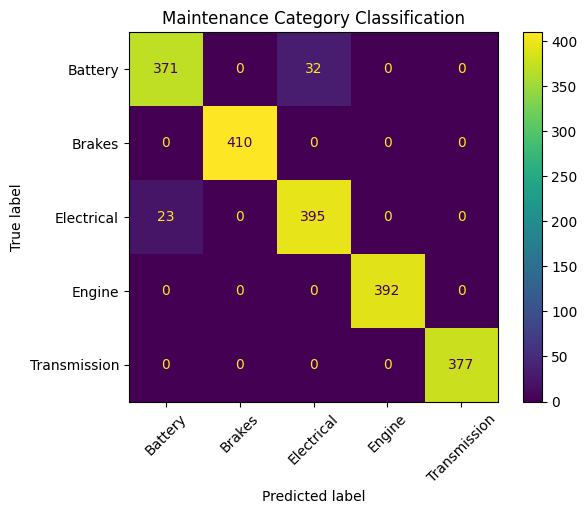

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title(
    "Maintenance Category Classification"
)

plt.show()

In [25]:
import os
import joblib

# Define the folder for saving models
model_dir = "/content/drive/MyDrive/AutoSenseAI/models"

# Create the folder if it does not exist
os.makedirs(model_dir, exist_ok=True)

# Save maintenance category model
model_path = os.path.join(
    model_dir,
    "maintenance_category_xgboost.pkl"
)

joblib.dump(
    diagnostic_pipeline,
    model_path
)

# Save label encoder
encoder_path = os.path.join(
    model_dir,
    "maintenance_category_label_encoder.pkl"
)

joblib.dump(
    label_encoder,
    encoder_path
)

print("Model saved successfully!")
print("Model path:", model_path)
print("Encoder path:", encoder_path)

Model saved successfully!
Model path: /content/drive/MyDrive/AutoSenseAI/models/maintenance_category_xgboost.pkl
Encoder path: /content/drive/MyDrive/AutoSenseAI/models/maintenance_category_label_encoder.pkl


In [26]:
new_vehicle = pd.DataFrame(
    [
        {
            "Car_Make": "Toyota",
            "Car_Model": "Corolla",
            "Vehicle_Year": 2018,
            "Problem Description": "Brake noise",
            "Severity": "High",
            "Diagnosis": "Worn brake pads",
            "ECU Data": "Unknown",
            "Service History": "Brake service 1 year ago"
        }
    ]
)

In [27]:
prediction = diagnostic_pipeline.predict(
    new_vehicle
)

probabilities = diagnostic_pipeline.predict_proba(
    new_vehicle
)

In [28]:
predicted_class = label_encoder.inverse_transform(
    prediction
)[0]

confidence = probabilities.max()

print(
    "Predicted Maintenance Category:",
    predicted_class
)

print(
    "Confidence:",
    round(
        confidence * 100,
        2
    ),
    "%"
)

Predicted Maintenance Category: Brakes
Confidence: 99.88 %
